In [11]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


First, we load our files, and just see what the data looks like

In [20]:
# below transition
d1 = find_file("241206_TS_Isooctane_W20_20mM_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("241206_TS_Isooctane_W20_20mM_run2.DSC", exp_type="francklab_esr/romana") # heating 1 subsequently --after cooling and heating

In [21]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (85, 'Temperature'), (10, 'harmonic')]

In [22]:
d2.shape

[(1024, '$B_0$'), (85, 'Temperature'), (10, 'harmonic')]

In [23]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (85, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [24]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (85, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'cooling1')

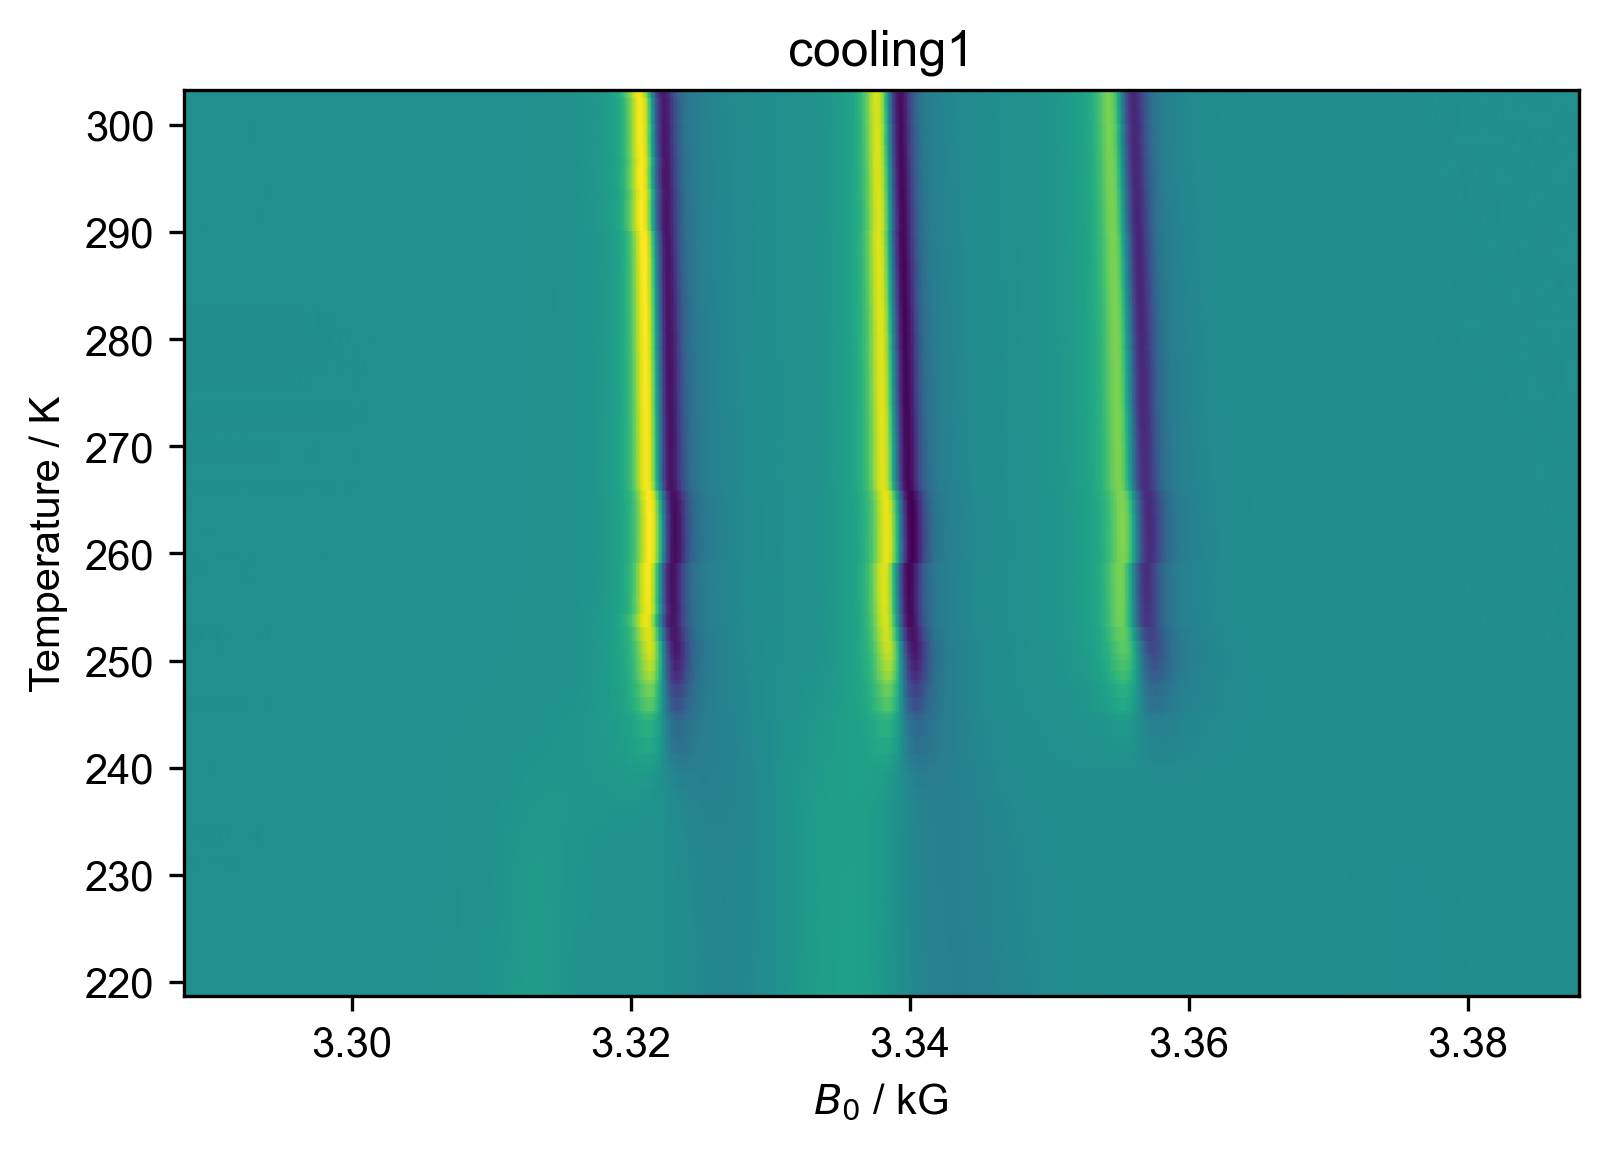

In [25]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("cooling1")

Text(0.5, 1.0, 'heating1')

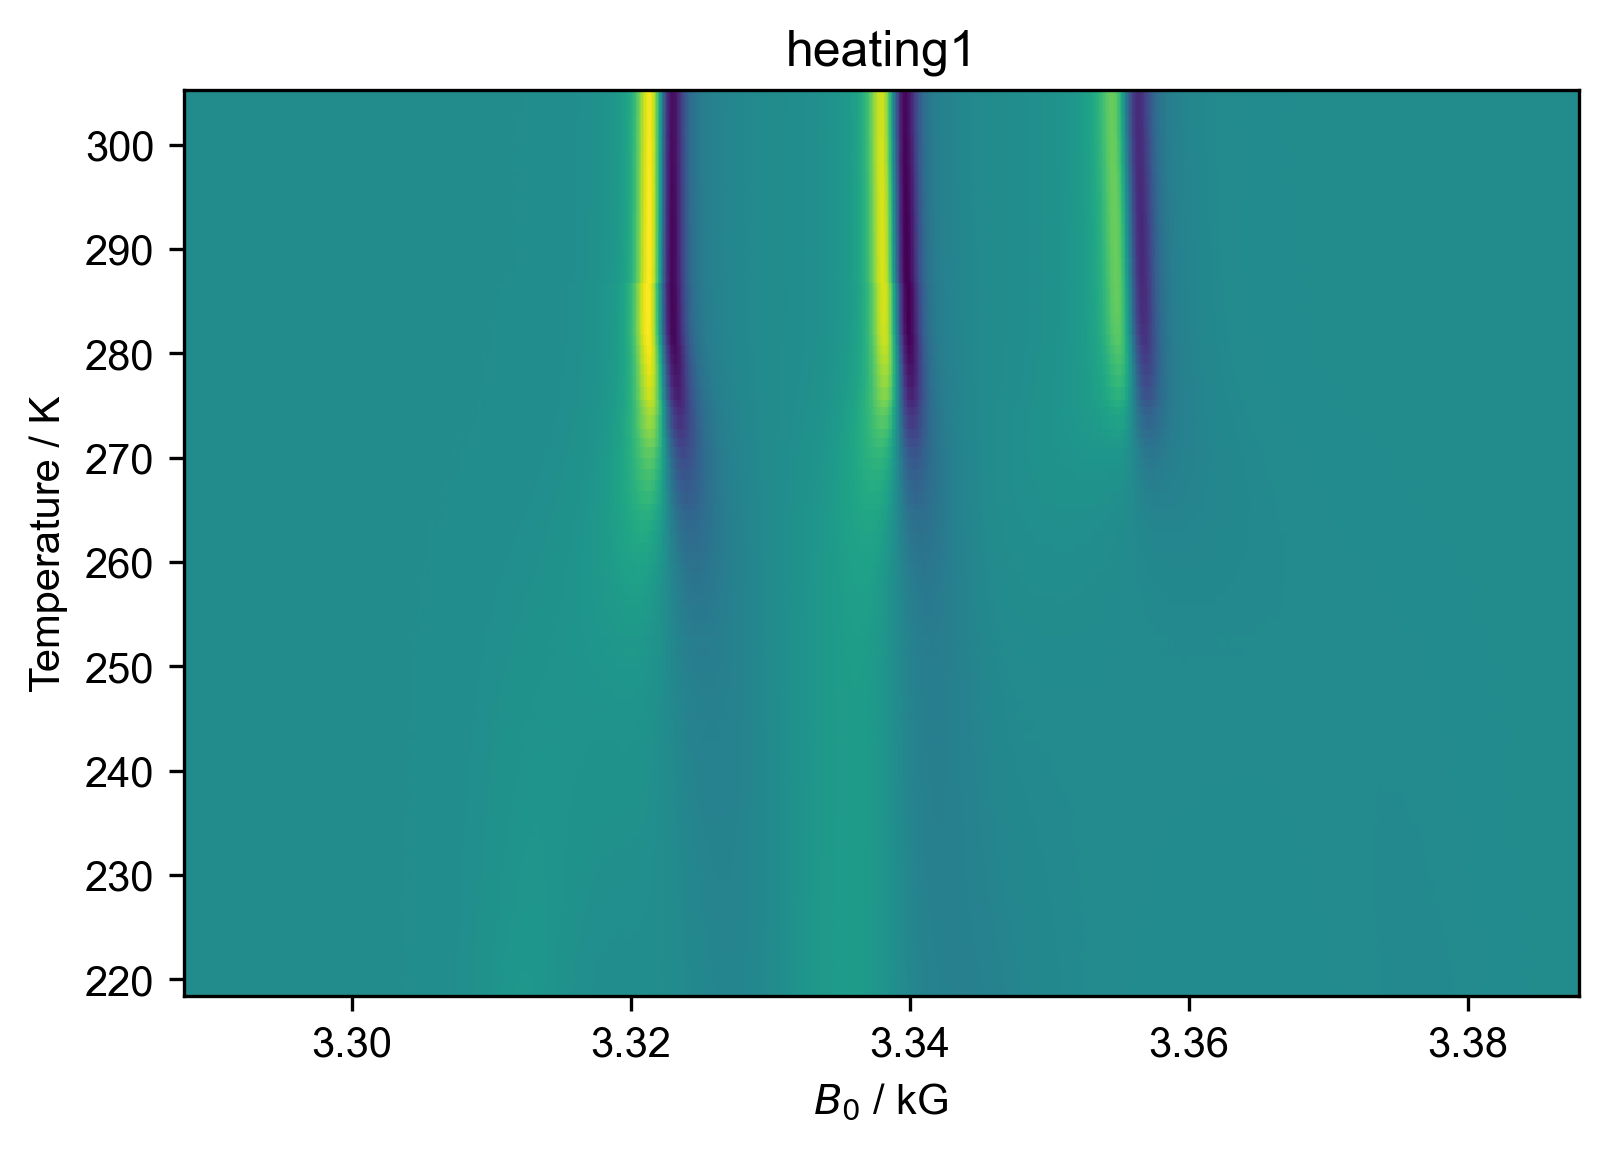

In [26]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("heating1")

In [27]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in Isooctane for cooling", (None, None))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

ValueError: ('you can only use the range format on data where the axis is in consecutively increasing or decreasing order, and the differences that I see are [0.686 1.992 0.766 0.    0.722 1.44  0.633 0.97  1.61  0.573 1.49  0.833\n 0.305 1.011 2.124 0.22  1.03  1.588 0.178 1.745 1.182 0.651 1.029 2.185\n 1.022 0.013 0.671 1.86  0.602 0.027 1.705 0.359 0.917 1.326 1.403 1.057\n 0.672 0.738 1.684 0.275 1.548 0.654 1.765 0.73  1.315 1.468 0.078 0.245\n 1.36  1.923 1.425 0.371 1.048 0.42  0.839 0.622 2.566 0.635 1.474 0.355\n 0.648 1.586 1.318 0.279 1.191 1.102 0.747 0.974 1.15  1.187 0.631 0.328\n 1.071 1.487 0.289 1.811 0.176 1.933 0.012 2.13  0.213 1.4   1.337 0.748]', 'if you like, you can still do this by first calling .sort( on the Temperature axis')

In [28]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=20$ in Dodecane for heating1", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

ValueError: ('you can only use the range format on data where the axis is in consecutively increasing or decreasing order, and the differences that I see are [1.228 1.053 0.965 1.005 1.059 0.831 1.11  0.856 0.881 0.809 1.698 0.346\n 1.868 0.    2.039 0.206 1.206 0.876 1.772 0.069 1.005 2.005 0.054 1.741\n 0.148 1.948 0.161 1.806 0.201 1.893 0.053 1.979 0.067 1.88  0.409 0.7\n 1.871 0.329 1.8   0.065 1.795 0.157 1.776 0.521 1.523 0.481 0.649 1.864\n 0.297 1.803 0.309 1.754 0.013 1.667 0.927 0.571 0.864 1.715 0.521 1.651\n 0.139 1.574 0.304 1.889 0.101 2.077 0.443 0.709 0.391 1.037 1.262 1.249\n 0.832 1.071 1.019 1.181 0.39  1.569 0.651 0.577 2.04  0.3   0.887 2.445]', 'if you like, you can still do this by first calling .sort( on the Temperature axis')

[218.998 219.684 221.676 222.442 222.442 223.164 224.604 225.237 226.207
 227.817 228.39  229.88  230.713 231.018 232.029 234.153 234.373 235.403
 236.991 237.169 238.914 240.096 240.747 241.776 243.961 244.983 244.996
 245.667 247.527 248.129 248.156 249.861 250.22  251.137 252.463 253.866
 254.923 255.595 256.333 258.017 258.292 259.84  260.494 262.259 262.989
 264.304 265.772 265.85  266.095 267.455 269.378 270.803 271.174 272.222
 272.642 273.481 274.103 276.669 277.304 278.778 279.133 279.781 281.367
 282.685 282.964 284.155 285.257 286.004 286.978 288.128 289.315 289.946
 290.274 291.345 292.832 293.121 294.932 295.108 297.041 297.053 299.183
 299.396 300.796 302.133 302.881]
[218.998 220.226 221.279 222.244 223.249 224.308 225.139 226.249 227.105
 227.986 228.795 230.493 230.839 232.707 232.707 234.746 234.952 236.158
 237.034 238.806 238.875 239.88  241.885 241.939 243.68  243.828 245.776
 245.937 247.743 247.944 249.837 249.89  251.869 251.936 253.816 254.225
 254.925 256.796 

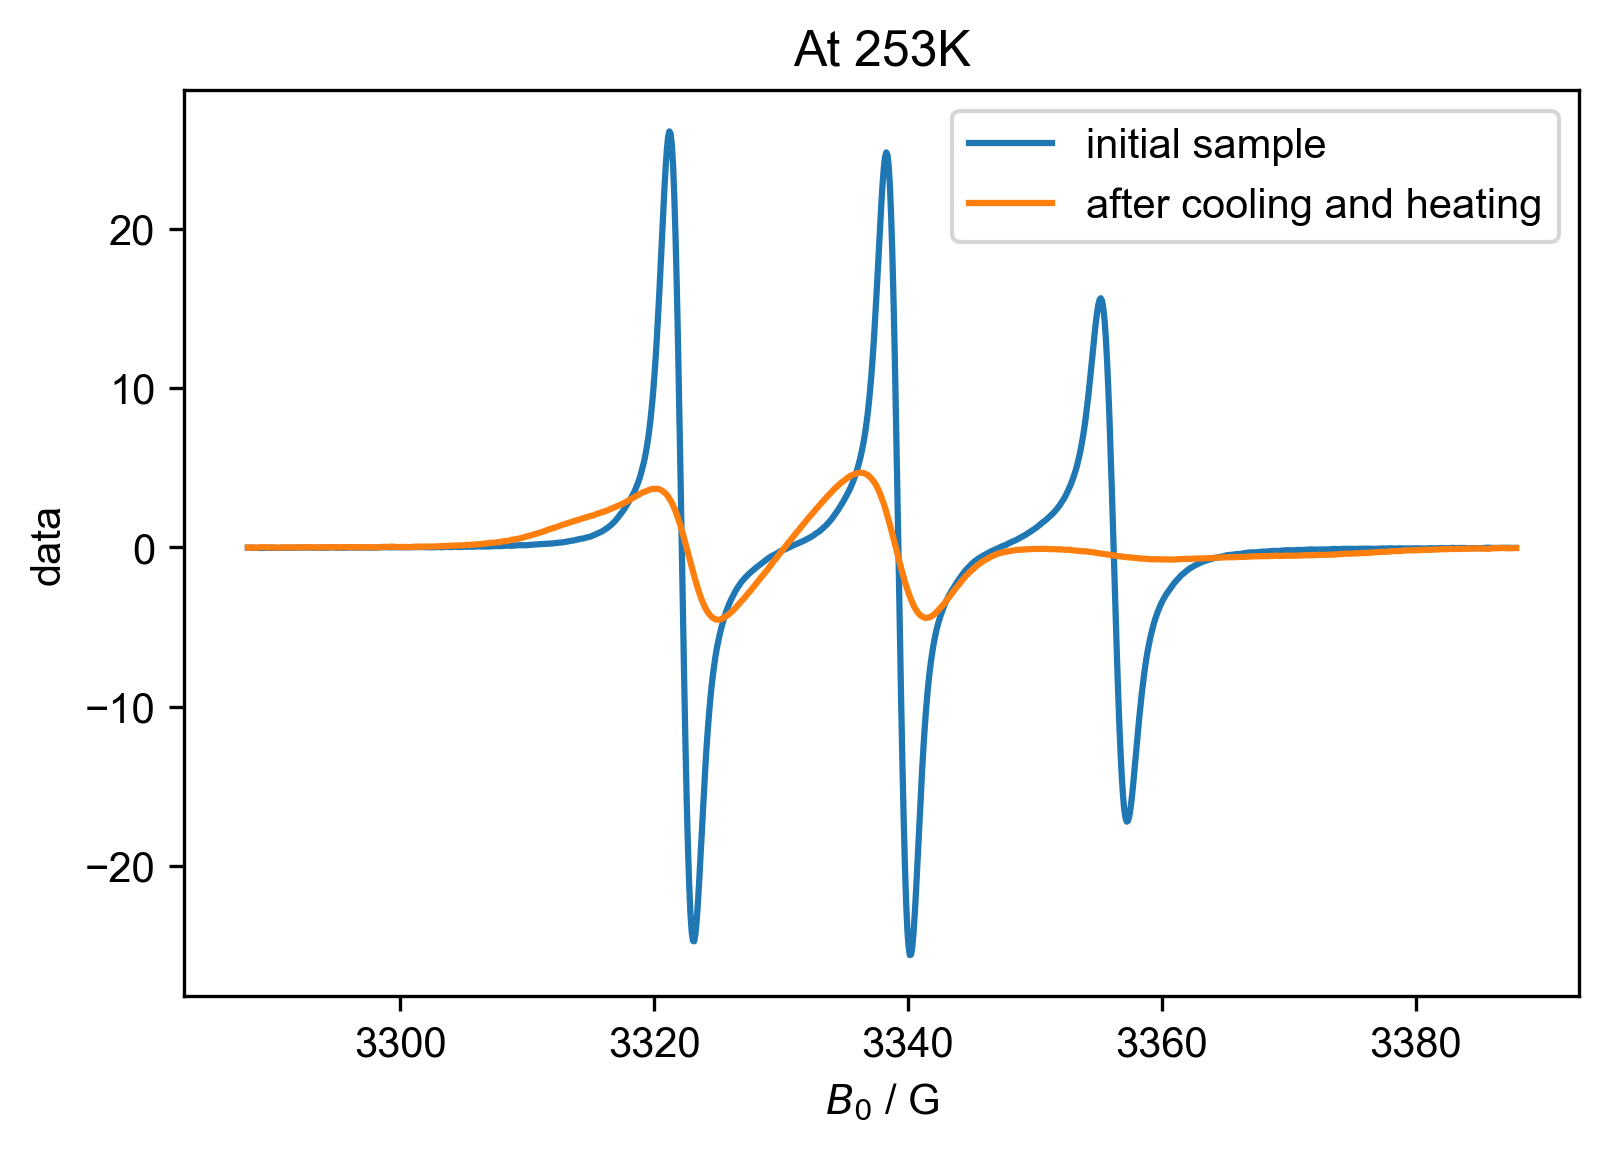

In [29]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[218.998 219.684 221.676 222.442 222.442 223.164 224.604 225.237 226.207
 227.817 228.39  229.88  230.713 231.018 232.029 234.153 234.373 235.403
 236.991 237.169 238.914 240.096 240.747 241.776 243.961 244.983 244.996
 245.667 247.527 248.129 248.156 249.861 250.22  251.137 252.463 253.866
 254.923 255.595 256.333 258.017 258.292 259.84  260.494 262.259 262.989
 264.304 265.772 265.85  266.095 267.455 269.378 270.803 271.174 272.222
 272.642 273.481 274.103 276.669 277.304 278.778 279.133 279.781 281.367
 282.685 282.964 284.155 285.257 286.004 286.978 288.128 289.315 289.946
 290.274 291.345 292.832 293.121 294.932 295.108 297.041 297.053 299.183
 299.396 300.796 302.133 302.881]
[218.998 220.226 221.279 222.244 223.249 224.308 225.139 226.249 227.105
 227.986 228.795 230.493 230.839 232.707 232.707 234.746 234.952 236.158
 237.034 238.806 238.875 239.88  241.885 241.939 243.68  243.828 245.776
 245.937 247.743 247.944 249.837 249.89  251.869 251.936 253.816 254.225
 254.925 256.796 

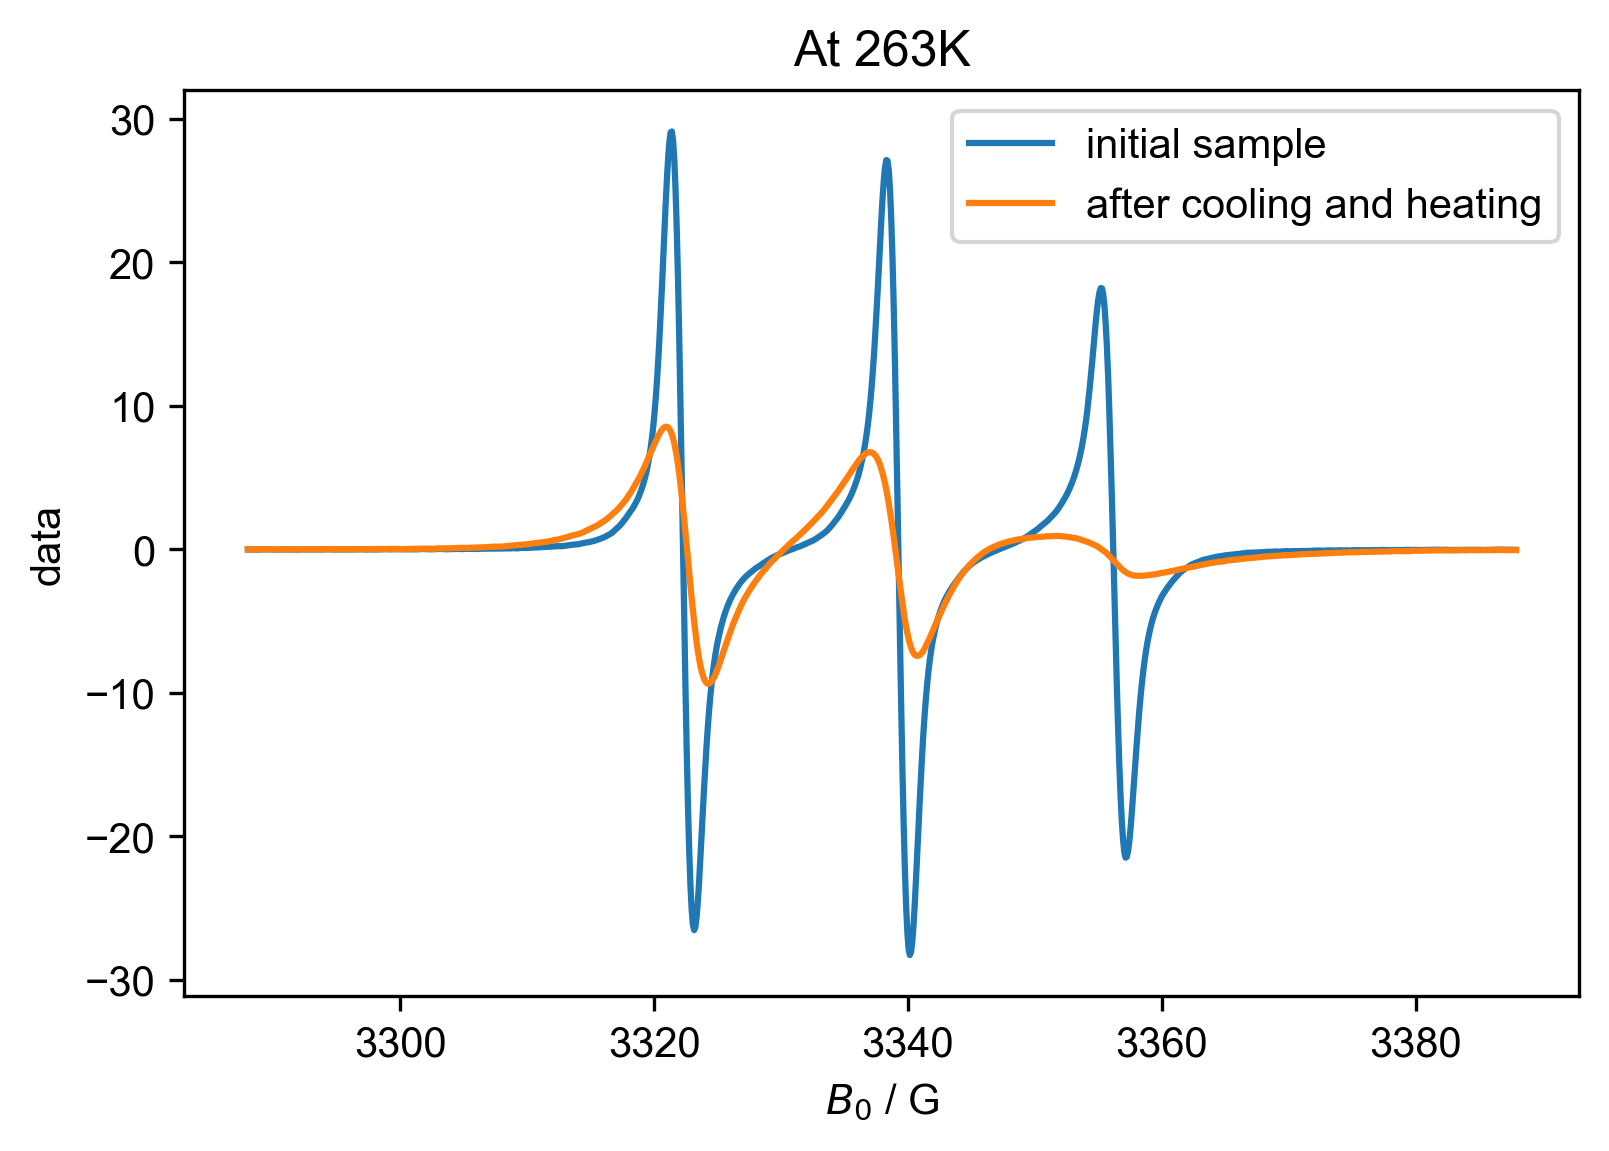

In [30]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[218.998 219.684 221.676 222.442 222.442 223.164 224.604 225.237 226.207
 227.817 228.39  229.88  230.713 231.018 232.029 234.153 234.373 235.403
 236.991 237.169 238.914 240.096 240.747 241.776 243.961 244.983 244.996
 245.667 247.527 248.129 248.156 249.861 250.22  251.137 252.463 253.866
 254.923 255.595 256.333 258.017 258.292 259.84  260.494 262.259 262.989
 264.304 265.772 265.85  266.095 267.455 269.378 270.803 271.174 272.222
 272.642 273.481 274.103 276.669 277.304 278.778 279.133 279.781 281.367
 282.685 282.964 284.155 285.257 286.004 286.978 288.128 289.315 289.946
 290.274 291.345 292.832 293.121 294.932 295.108 297.041 297.053 299.183
 299.396 300.796 302.133 302.881]
[218.998 220.226 221.279 222.244 223.249 224.308 225.139 226.249 227.105
 227.986 228.795 230.493 230.839 232.707 232.707 234.746 234.952 236.158
 237.034 238.806 238.875 239.88  241.885 241.939 243.68  243.828 245.776
 245.937 247.743 247.944 249.837 249.89  251.869 251.936 253.816 254.225
 254.925 256.796 

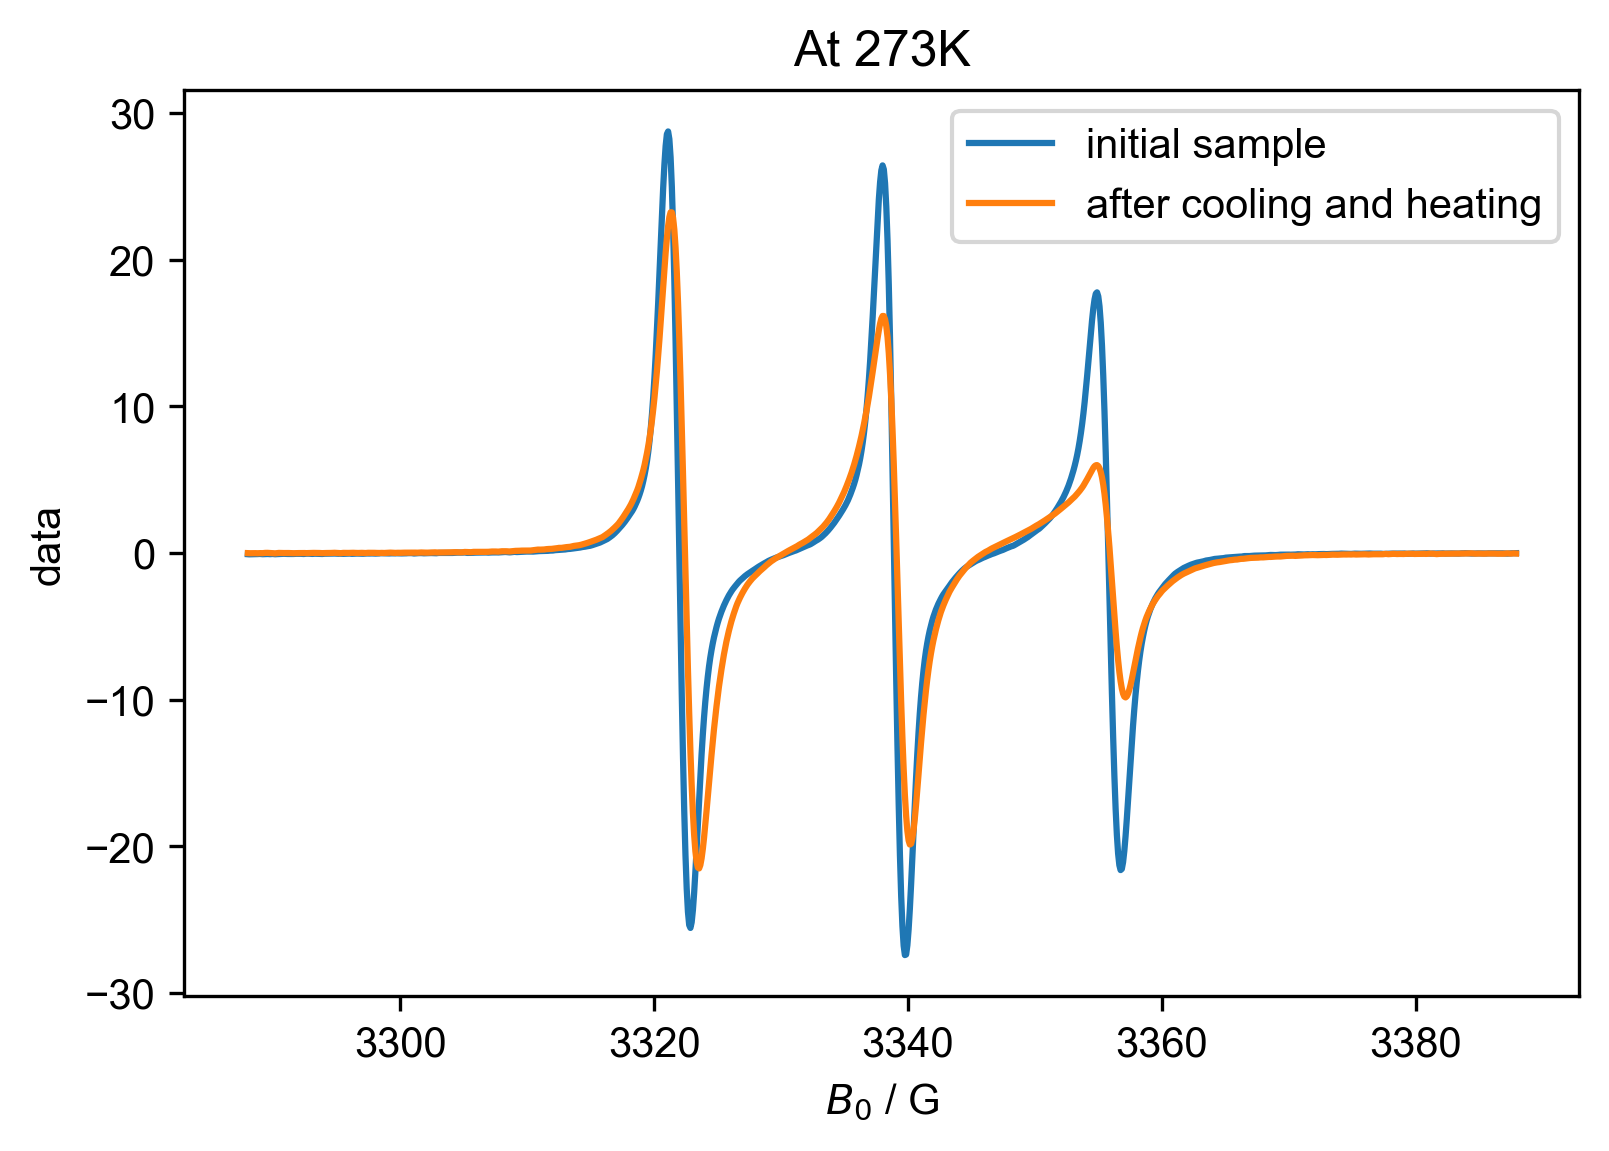

In [31]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[218.998 219.684 221.676 222.442 222.442 223.164 224.604 225.237 226.207
 227.817 228.39  229.88  230.713 231.018 232.029 234.153 234.373 235.403
 236.991 237.169 238.914 240.096 240.747 241.776 243.961 244.983 244.996
 245.667 247.527 248.129 248.156 249.861 250.22  251.137 252.463 253.866
 254.923 255.595 256.333 258.017 258.292 259.84  260.494 262.259 262.989
 264.304 265.772 265.85  266.095 267.455 269.378 270.803 271.174 272.222
 272.642 273.481 274.103 276.669 277.304 278.778 279.133 279.781 281.367
 282.685 282.964 284.155 285.257 286.004 286.978 288.128 289.315 289.946
 290.274 291.345 292.832 293.121 294.932 295.108 297.041 297.053 299.183
 299.396 300.796 302.133 302.881]
[218.998 220.226 221.279 222.244 223.249 224.308 225.139 226.249 227.105
 227.986 228.795 230.493 230.839 232.707 232.707 234.746 234.952 236.158
 237.034 238.806 238.875 239.88  241.885 241.939 243.68  243.828 245.776
 245.937 247.743 247.944 249.837 249.89  251.869 251.936 253.816 254.225
 254.925 256.796 

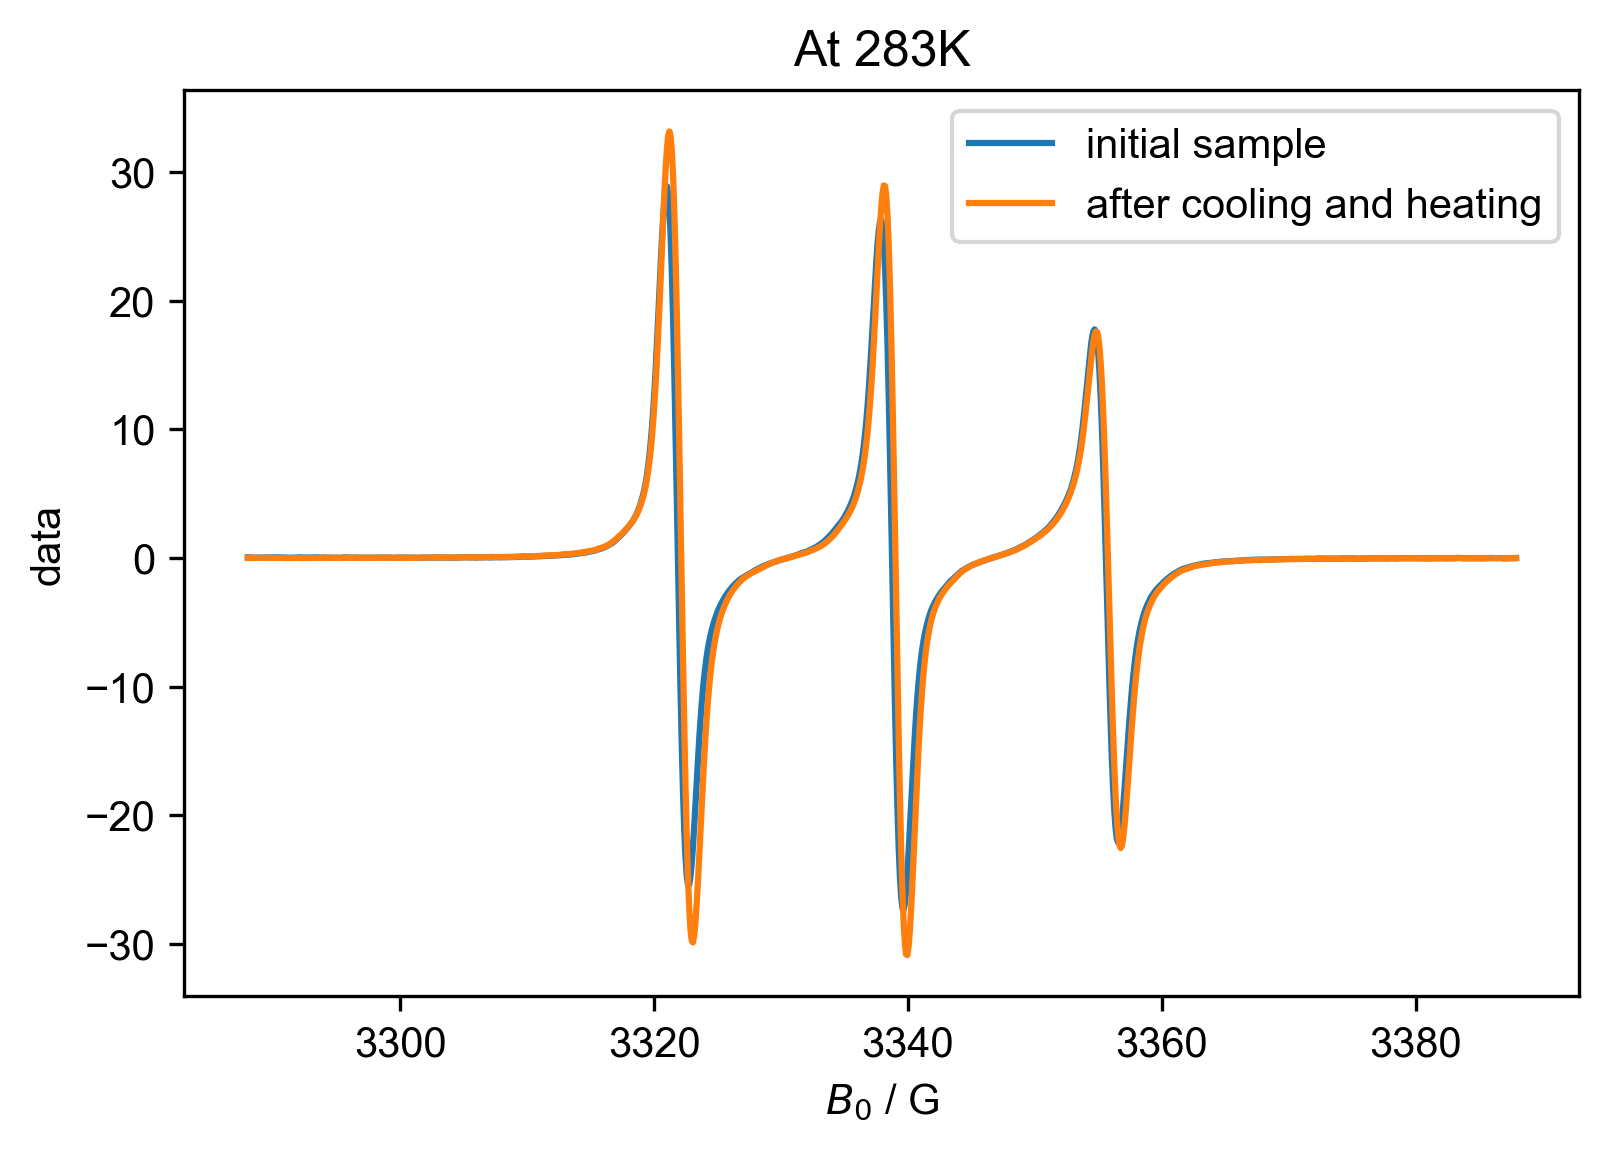

In [32]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

In [33]:
# #Normalized
# figure(dpi=300, figsize=(7,4))
# plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
# plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
# title("Normalized TEMPO-SO$_4$ w$_0= 20$ in Dodecane near room temperature (283K)")
# legend()